# Actividad de la Unidad 3: distribuciones continuas, estimación y prueba de hipótesis

**Universidad de Cartagena** · Ingeniería de Software · Probabilidad y Estadística
**Autor:** Jairo Alonso Osorio Cruz

En este notebook verifico con Python los ejercicios de la actividad. Los ejercicios 1 a 13 los compruebo con los datos que trae el enunciado, y el ejercicio 14 lo resuelvo con la base de datos del curso, `CFBD273_Base_de_Datos_1000_registros.xlsx`.

El enunciado sugiere Google Colab; yo trabajé en Jupyter dentro de PyCharm con un entorno virtual propio. El código es el mismo en los dos casos.

## 0. Preparación

Cargo las librerías y defino las rutas del proyecto. Las rutas se calculan a partir de la carpeta del notebook, así que el archivo funciona sin importar dónde esté clonado el repositorio. Todas las gráficas se guardan en `figures/`.

In [1]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy import stats

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RUTA_BASE = RAIZ / "data" / "CFBD273_Base_de_Datos_1000_registros.xlsx"
CARPETA_FIGURAS = RAIZ / "figures"
CARPETA_FIGURAS.mkdir(exist_ok=True)


def guardar_figura(fig, nombre):
    """Guarda una figura en figures/ con buena resolución para el informe."""
    fig.savefig(CARPETA_FIGURAS / nombre, dpi=200, bbox_inches="tight")


print("numpy", np.__version__, "| pandas", pd.__version__,
      "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__)
print("Base encontrada:", RUTA_BASE.exists())

numpy 2.5.4 | pandas 3.1.1 | scipy 1.18.1 | matplotlib 3.11.2
Base encontrada: True


## 1. Carga y validación de la base

Antes de usar la base reviso que sea el archivo correcto: qué hojas trae, cuántas filas y columnas tiene la hoja `Datos`, de qué tipo es cada columna y si la columna del ejercicio 14, `Duracion_Despliegue_min`, tiene valores faltantes.

In [2]:
hojas = pd.ExcelFile(RUTA_BASE).sheet_names
print("Hojas del archivo:", hojas)

datos = pd.read_excel(RUTA_BASE, sheet_name="Datos")
print("Dimensiones de la hoja Datos:", datos.shape)

Hojas del archivo: ['Datos', 'Diccionario de variables']
Dimensiones de la hoja Datos: (1000, 20)


In [3]:
datos.dtypes.to_frame("tipo")

,tipo
ID_Modulo,int64
Codigo_Modulo,str
Equipo,str
Lenguaje,str
Prioridad,str
Sistema_Operativo,str
Tipo_Incidente,str
Tamano_KLOC,float64
Defectos_Corregidos,int64
Tiempo_Respuesta_ms,float64


In [4]:
COLUMNA = "Duracion_Despliegue_min"
duracion = datos[COLUMNA]

print("Tipo de dato:", duracion.dtype)
print("Valores faltantes:", duracion.isna().sum())
print("Registros:", duracion.count())
print("Mínimo:", duracion.min(), "min | Máximo:", duracion.max(), "min")

Tipo de dato: float64
Valores faltantes: 0
Registros: 1000
Mínimo: 2.0 min | Máximo: 27.4 min


La hoja `Diccionario de variables` describe cada columna. Busco la fila de `Duracion_Despliegue_min` para confirmar cómo la clasifica el docente.

In [5]:
diccionario_crudo = pd.read_excel(RUTA_BASE, sheet_name="Diccionario de variables", header=None)
fila_encabezado = diccionario_crudo.index[diccionario_crudo[0] == "Variable"][0]
diccionario = pd.read_excel(RUTA_BASE, sheet_name="Diccionario de variables", header=fila_encabezado)
with pd.option_context("display.max_colwidth", None):
    print(diccionario[diccionario["Variable"] == COLUMNA].T.to_string(header=False))

Variable                                                                                      Duracion_Despliegue_min
Tipo de variable                                                                                Cuantitativa continua
Escala de medición                                                                                              Razón
Descripción / uso sugerido en el curso  Duración del despliegue en minutos. Para pruebas de hipótesis sobre la media.


La base tiene las dos hojas esperadas, la hoja `Datos` tiene 1.000 registros y 20 columnas, y `Duracion_Despliegue_min` es una variable numérica continua, en minutos, sin valores faltantes. Con eso puedo usarla directamente en el ejercicio 14.

## Estilo de las gráficas

Uso los mismos colores en todas las figuras: azul para la curva y las áreas principales, y naranja para la región que pide cada literal.

In [6]:
from matplotlib.ticker import FuncFormatter

AZUL = "#2a78d6"
NARANJA = "#eb6834"
TEXTO = "#0b0b0b"
TEXTO_SECUNDARIO = "#52514e"
CUADRICULA = "#e4e3df"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": TEXTO_SECUNDARIO,
    "axes.labelcolor": TEXTO,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": CUADRICULA,
    "grid.linewidth": 0.6,
    "xtick.color": TEXTO_SECUNDARIO,
    "ytick.color": TEXTO_SECUNDARIO,
    "legend.frameon": False,
    "font.size": 10,
})


def coma(valor, decimales=4):
    """Escribe un número con coma decimal, como se usa en español."""
    return f"{valor:.{decimales}f}".replace(".", ",")


def ejes_con_coma(eje):
    """Muestra las marcas de los dos ejes con coma decimal."""
    formato = FuncFormatter(lambda v, _: f"{v:g}".replace(".", ","))
    eje.xaxis.set_major_formatter(formato)
    eje.yaxis.set_major_formatter(formato)

# Subtema 1. Distribuciones continuas

## Ejercicio 1. Normal y estandarización

El tiempo de respuesta de la API sigue una normal con media 200 ms y desviación 30 ms, X ~ N(200, 30). Para cada literal estandarizo con z = (x − μ)/σ y busco el área bajo la normal estándar. Abajo comparo el valor exacto de `scipy.stats.norm` con el que sale de la tabla, que redondea z a dos decimales.

In [7]:
mu_1, sigma_1 = 200, 30
api = stats.norm(loc=mu_1, scale=sigma_1)

# a) P(X < 250)
z_a = (250 - mu_1) / sigma_1
p_a = api.cdf(250)

# b) P(X > 260): cola derecha, se usa la función de supervivencia sf = 1 - cdf
z_b = (260 - mu_1) / sigma_1
p_b = api.sf(260)

# c) Percentil 95: primero el z que deja 0,95 a la izquierda y luego x = μ + zσ
z_c = stats.norm.ppf(0.95)
p95 = api.ppf(0.95)

ejercicio_1 = pd.DataFrame({
    "literal": ["a) P(X < 250)", "b) P(X > 260)", "c) percentil 95"],
    "z": [z_a, z_b, z_c],
    "resultado": [p_a, p_b, p95],
})
ejercicio_1.round(4)

,literal,z,resultado
0,a) P(X < 250),1.6667,0.9522
1,b) P(X > 260),2.0000,0.0228
2,c) percentil 95,1.6449,249.3456


In [8]:
# Valores con z redondeado a dos decimales, como en la tabla normal estándar
print("Tabla, Φ(1,67) =", round(stats.norm.cdf(1.67), 4))
print("Tabla, 1 − Φ(2,00) =", round(stats.norm.sf(2.00), 4))
print("Tabla, Φ(1,64) =", round(stats.norm.cdf(1.64), 4), "| Φ(1,65) =", round(stats.norm.cdf(1.65), 4))
print("Percentil 95 con z = 1,645:", 200 + 1.645 * 30, "ms")

Tabla, Φ(1,67) = 0.9525
Tabla, 1 − Φ(2,00) = 0.0228
Tabla, Φ(1,64) = 0.9495 | Φ(1,65) = 0.9505
Percentil 95 con z = 1,645: 249.35 ms


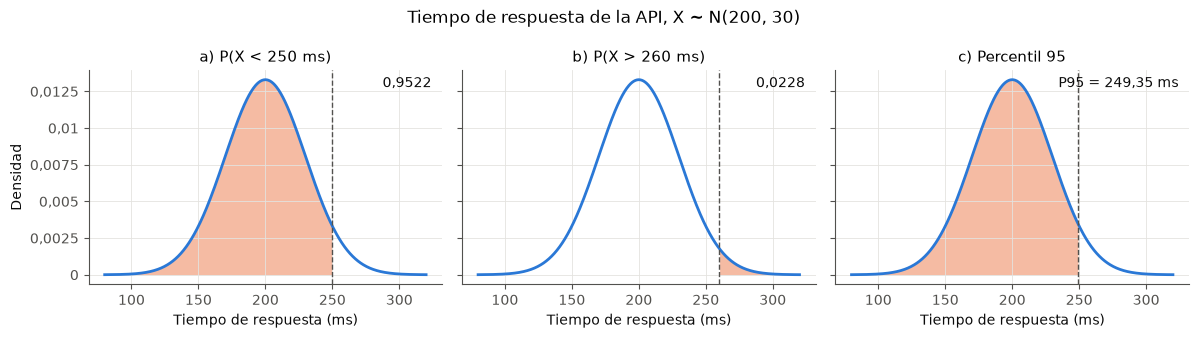

In [9]:
x = np.linspace(mu_1 - 4 * sigma_1, mu_1 + 4 * sigma_1, 600)
y = api.pdf(x)

fig, ejes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
casos = [
    ("a) P(X < 250 ms)", x <= 250, coma(p_a), 250),
    ("b) P(X > 260 ms)", x >= 260, coma(p_b), 260),
    ("c) Percentil 95", x <= p95, f"P95 = {coma(p95, 2)} ms", p95),
]
for eje, (titulo, region, etiqueta, corte) in zip(ejes, casos):
    eje.plot(x, y, color=AZUL, linewidth=2)
    eje.fill_between(x, y, where=region, color=NARANJA, alpha=0.45, linewidth=0)
    eje.axvline(corte, color=TEXTO_SECUNDARIO, linewidth=1, linestyle="--")
    eje.set_title(titulo)
    eje.set_xlabel("Tiempo de respuesta (ms)")
    eje.text(0.97, 0.92, etiqueta, transform=eje.transAxes, ha="right", color=TEXTO)
    ejes_con_coma(eje)
ejes[0].set_ylabel("Densidad")
fig.suptitle("Tiempo de respuesta de la API, X ~ N(200, 30)", fontsize=12)
fig.tight_layout()
guardar_figura(fig, "ej01_normal_tiempo_respuesta.png")
plt.show()

Con estos resultados, cerca del 95,2 % de las peticiones responde en menos de 250 ms y solo un 2,3 % pasa de 260 ms. El 95 % de las peticiones queda por debajo de 249,35 ms, así que un SLA de "95 % de las peticiones en menos de 250 ms" es coherente con el comportamiento del servicio.

## Ejercicio 2. Regla empírica

El uso de CPU sigue una normal con media 60 % y desviación 8 %, X ~ N(60, 8). La regla empírica dice que alrededor del 68 % de los datos está a una desviación de la media y alrededor del 95 % a dos desviaciones. Comparo esos porcentajes aproximados con las áreas exactas de la normal.

In [10]:
mu_2, sigma_2 = 60, 8
cpu = stats.norm(loc=mu_2, scale=sigma_2)

rango_68 = (mu_2 - sigma_2, mu_2 + sigma_2)
rango_95 = (mu_2 - 2 * sigma_2, mu_2 + 2 * sigma_2)

area_exacta_1s = cpu.cdf(rango_68[1]) - cpu.cdf(rango_68[0])
area_exacta_2s = cpu.cdf(rango_95[1]) - cpu.cdf(rango_95[0])

# c) 76 % está justo a dos desviaciones: fuera del 95 % queda un 5 %, la mitad en cada cola
p_76_regla = (1 - 0.95) / 2
p_76_exacta = cpu.sf(76)

print(f"a) Rango del 68 %: {rango_68[0]} % a {rango_68[1]} %  (área exacta {area_exacta_1s:.4f})")
print(f"b) Rango del 95 %: {rango_95[0]} % a {rango_95[1]} %  (área exacta {area_exacta_2s:.4f})")
print(f"c) P(CPU > 76 %): regla empírica {p_76_regla:.4f} | normal exacta {p_76_exacta:.4f}  (z = {(76 - mu_2) / sigma_2:.0f})")

a) Rango del 68 %: 52 % a 68 %  (área exacta 0.6827)
b) Rango del 95 %: 44 % a 76 %  (área exacta 0.9545)
c) P(CPU > 76 %): regla empírica 0.0250 | normal exacta 0.0228  (z = 2)


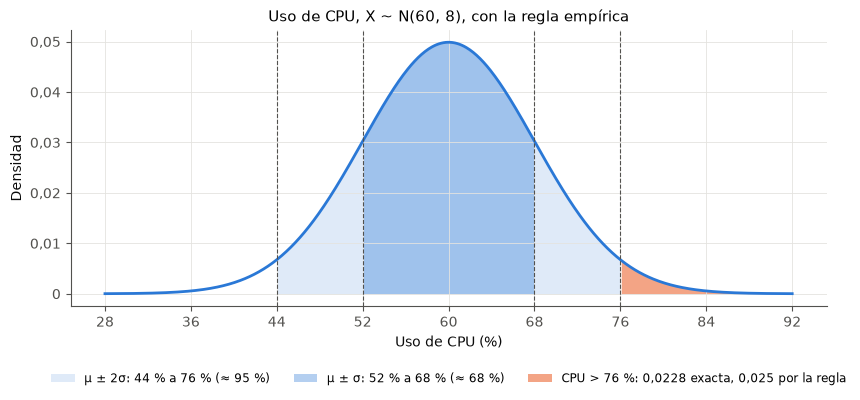

In [11]:
x = np.linspace(mu_2 - 4 * sigma_2, mu_2 + 4 * sigma_2, 600)
y = cpu.pdf(x)

fig, eje = plt.subplots(figsize=(9, 4.2))
eje.plot(x, y, color=AZUL, linewidth=2)
eje.fill_between(x, y, where=(x >= rango_95[0]) & (x <= rango_95[1]), color=AZUL, alpha=0.15,
                 linewidth=0, label="μ ± 2σ: 44 % a 76 % (≈ 95 %)")
eje.fill_between(x, y, where=(x >= rango_68[0]) & (x <= rango_68[1]), color=AZUL, alpha=0.35,
                 linewidth=0, label="μ ± σ: 52 % a 68 % (≈ 68 %)")
eje.fill_between(x, y, where=x >= 76, color=NARANJA, alpha=0.6, linewidth=0,
                 label=f"CPU > 76 %: {coma(p_76_exacta)} exacta, 0,025 por la regla")
for limite in (*rango_95, *rango_68):
    eje.axvline(limite, color=TEXTO_SECUNDARIO, linewidth=0.8, linestyle="--")
eje.set_xticks([28, 36, 44, 52, 60, 68, 76, 84, 92])
eje.set_xlabel("Uso de CPU (%)")
eje.set_ylabel("Densidad")
eje.set_title("Uso de CPU, X ~ N(60, 8), con la regla empírica")
ejes_con_coma(eje)
eje.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=8.5)
fig.tight_layout()
guardar_figura(fig, "ej02_regla_empirica_cpu.png")
plt.show()

En operación normal el uso de CPU se mueve casi siempre entre 44 % y 76 %. Un valor por encima de 76 % solo aparece en cerca del 2,5 % de las mediciones (2,28 % con la normal exacta), así que lo tomo como umbral de alerta de saturación. El rango de 52 % a 68 % describe el comportamiento típico del servidor.

## Ejercicio 3. Exponencial

El tiempo entre llegadas de peticiones al balanceador sigue una exponencial con media μ = 4 s. La tasa es el inverso de la media, λ = 1/μ, y las probabilidades salen de P(X > x) = e^(−λx) y P(X < x) = 1 − e^(−λx). En `scipy.stats.expon` el parámetro `scale` es la media, no la tasa.

In [12]:
media_3 = 4
tasa = 1 / media_3
llegadas = stats.expon(scale=media_3)

p_mas_8 = llegadas.sf(8)      # P(X > 8)
p_menos_2 = llegadas.cdf(2)   # P(X < 2)

print(f"a) λ = 1/{media_3} = {tasa} llegadas por segundo")
print(f"b) P(X > 8 s) = e^(−{tasa}·8) = {p_mas_8:.4f}   (a mano: e^(−2) = {np.exp(-2):.4f})")
print(f"c) P(X < 2 s) = 1 − e^(−{tasa}·2) = {p_menos_2:.4f}   (a mano: 1 − e^(−0,5) = {1 - np.exp(-0.5):.4f})")

a) λ = 1/4 = 0.25 llegadas por segundo
b) P(X > 8 s) = e^(−0.25·8) = 0.1353   (a mano: e^(−2) = 0.1353)
c) P(X < 2 s) = 1 − e^(−0.25·2) = 0.3935   (a mano: 1 − e^(−0,5) = 0.3935)


Para la interpretación también calculo dos datos de apoyo: la falta de memoria, que dice que haber esperado ya 5 s no cambia la probabilidad de esperar 8 s más, y el tiempo que solo se supera en el 1 % de los intervalos entre llegadas.

In [13]:
# Falta de memoria: P(X > 5 + 8 | X > 5) es igual a P(X > 8)
p_condicional = llegadas.sf(5 + 8) / llegadas.sf(5)
print(f"P(X > 13 | X > 5) = {p_condicional:.4f}  frente a  P(X > 8) = {p_mas_8:.4f}")

# Tiempo que solo se supera en el 1 % de los intervalos
t_99 = llegadas.ppf(0.99)
print(f"Percentil 99 del tiempo entre llegadas: {t_99:.2f} s")

P(X > 13 | X > 5) = 0.1353  frente a  P(X > 8) = 0.1353
Percentil 99 del tiempo entre llegadas: 18.42 s


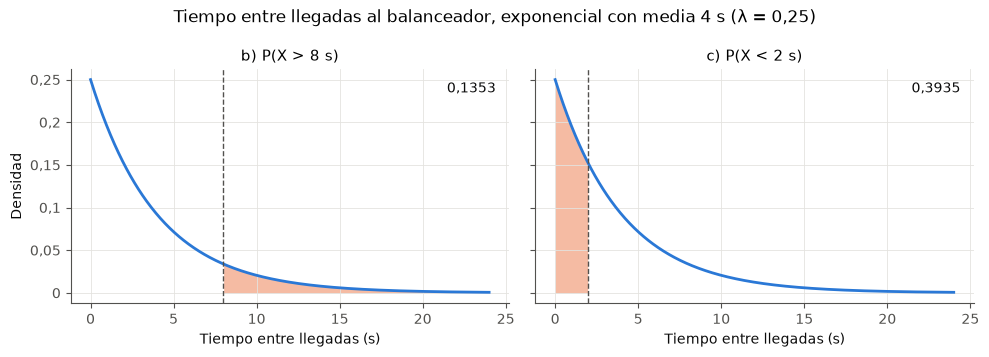

In [14]:
x = np.linspace(0, 24, 600)
y = llegadas.pdf(x)

fig, ejes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
casos = [
    ("b) P(X > 8 s)", x >= 8, coma(p_mas_8), 8),
    ("c) P(X < 2 s)", x <= 2, coma(p_menos_2), 2),
]
for eje, (titulo, region, etiqueta, corte) in zip(ejes, casos):
    eje.plot(x, y, color=AZUL, linewidth=2)
    eje.fill_between(x, y, where=region, color=NARANJA, alpha=0.45, linewidth=0)
    eje.axvline(corte, color=TEXTO_SECUNDARIO, linewidth=1, linestyle="--")
    eje.set_title(titulo)
    eje.set_xlabel("Tiempo entre llegadas (s)")
    eje.text(0.97, 0.9, etiqueta, transform=eje.transAxes, ha="right", color=TEXTO)
    ejes_con_coma(eje)
ejes[0].set_ylabel("Densidad")
fig.suptitle("Tiempo entre llegadas al balanceador, exponencial con media 4 s (λ = 0,25)", fontsize=12)
fig.tight_layout()
guardar_figura(fig, "ej03_exponencial_llegadas.png")
plt.show()

Llega en promedio una petición cada 4 s. En el 13,5 % de los intervalos pasan más de 8 s sin llegadas, así que un tiempo de espera de 8 s para conexiones inactivas cortaría conexiones con bastante frecuencia en horas pico. Por la falta de memoria, el tiempo que ya lleva esperando una conexión no ayuda a predecir cuánto falta, y por eso el timeout se fija con la cola de la distribución: 18,42 s solo se supera en el 1 % de los intervalos.

## Ejercicio 4. Uniforme

El tamaño del archivo temporal es uniforme continuo entre a = 10 MB y b = 50 MB. Uso E(X) = (a + b)/2, Var(X) = (b − a)²/12 y, para una probabilidad, la proporción del intervalo que cumple la condición. En `scipy.stats.uniform` el intervalo se define con `loc = a` y `scale = b − a`.

In [15]:
a, b = 10, 50
archivo = stats.uniform(loc=a, scale=b - a)

esperado = archivo.mean()
varianza = archivo.var()
desviacion = archivo.std()
p_mas_40 = archivo.sf(40)

print(f"a) E(X) = ({a} + {b})/2 = {esperado} MB")
print(f"b) Var(X) = ({b} − {a})²/12 = {varianza:.2f} MB²   (desviación estándar = {desviacion:.2f} MB)")
print(f"c) P(X > 40) = ({b} − 40)/({b} − {a}) = {p_mas_40}")

a) E(X) = (10 + 50)/2 = 30.0 MB
b) Var(X) = (50 − 10)²/12 = 133.33 MB²   (desviación estándar = 11.55 MB)
c) P(X > 40) = (50 − 40)/(50 − 10) = 0.25


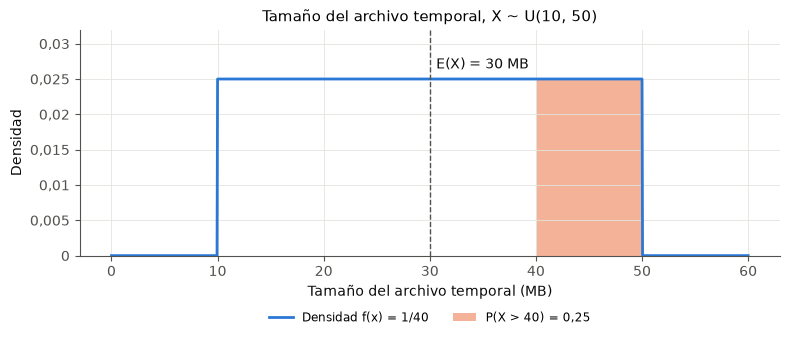

In [16]:
fig, eje = plt.subplots(figsize=(8, 3.6))
x = np.linspace(0, 60, 1201)
y = archivo.pdf(x)
eje.plot(x, y, color=AZUL, linewidth=2, label="Densidad f(x) = 1/40")
eje.fill_between(x, y, where=x >= 40, color=NARANJA, alpha=0.5, linewidth=0,
                 label=f"P(X > 40) = {coma(p_mas_40, 2)}")
eje.axvline(esperado, color=TEXTO_SECUNDARIO, linewidth=1, linestyle="--")
eje.text(esperado + 0.6, 0.0265, f"E(X) = {esperado:.0f} MB", color=TEXTO)
eje.set_ylim(0, 0.032)
eje.set_xlabel("Tamaño del archivo temporal (MB)")
eje.set_ylabel("Densidad")
eje.set_title("Tamaño del archivo temporal, X ~ U(10, 50)")
ejes_con_coma(eje)
eje.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=8.5)
fig.tight_layout()
guardar_figura(fig, "ej04_uniforme_archivos.png")
plt.show()

Un archivo temporal pesa en promedio 30 MB, con una desviación de 11,55 MB, y uno de cada cuatro pasa de 40 MB. Para planear el disco, el promedio sirve para estimar el consumo total de muchos archivos, pero como el tamaño nunca supera 50 MB, ese es el valor seguro para reservar espacio cuando varios procesos escriben a la vez.

# Subtema 2. Distribuciones de muestreo

## Ejercicio 5. t de Student, ji-cuadrada y F

Este ejercicio es conceptual y lo desarrollo completo en el informe. Aquí solo calculo los grados de libertad de los tres ejemplos que propongo, para tenerlos verificados.

In [17]:
# a) t de Student: 12 ejecuciones del pipeline de integración continua
n_pipeline = 12
print("a) t de Student, df = n − 1 =", n_pipeline - 1)

# b) Ji-cuadrada de independencia: Lenguaje (5 categorías) frente a Resultado_Prueba (2 categorías)
filas = datos["Lenguaje"].nunique()
columnas = datos["Resultado_Prueba"].nunique()
print(f"b) Ji-cuadrada, tabla de {filas} x {columnas}, df = ({filas} − 1)({columnas} − 1) =", (filas - 1) * (columnas - 1))

# c) F: tiempos de respuesta en dos servidores, 16 y 21 mediciones
n_1, n_2 = 16, 21
print(f"c) F, df numerador = {n_1 - 1}, df denominador = {n_2 - 1}")

a) t de Student, df = n − 1 = 11
b) Ji-cuadrada, tabla de 5 x 2, df = (5 − 1)(2 − 1) = 4
c) F, df numerador = 15, df denominador = 20


## Ejercicio 6. Comparación de varianzas con F

La versión A, que tomo como la anterior, tiene s² = 45 con n = 9, y la versión B, la nueva, tiene s² = 18 con n = 13. Como la pregunta es si la nueva logró estabilizar los tiempos de respuesta, planteo una prueba de una cola:

H₀: σ²_A = σ²_B  frente a  Hₐ: σ²_A > σ²_B, con α = 0,05.

El estadístico es F = s²_A / s²_B, con la varianza mayor en el numerador. También muestro el criterio de dos colas, que responde si las varianzas simplemente difieren.

In [18]:
s2_A, n_A = 45, 9
s2_B, n_B = 18, 13
alfa = 0.05

F = s2_A / s2_B
gl_num, gl_den = n_A - 1, n_B - 1

F_critico_1 = stats.f.ppf(1 - alfa, gl_num, gl_den)
F_critico_2 = stats.f.ppf(1 - alfa / 2, gl_num, gl_den)
p_una_cola = stats.f.sf(F, gl_num, gl_den)
p_dos_colas = 2 * p_una_cola

print(f"a) F = {s2_A}/{s2_B} = {F}")
print(f"b) Grados de libertad: numerador v1 = {gl_num}, denominador v2 = {gl_den}")
print(f"c) Una cola:  F crítico = {F_critico_1:.4f} | valor p = {p_una_cola:.4f} | rechazo H0: {F > F_critico_1}")
print(f"   Dos colas: F crítico = {F_critico_2:.4f} | valor p = {p_dos_colas:.4f} | rechazo H0: {F > F_critico_2}")

a) F = 45/18 = 2.5
b) Grados de libertad: numerador v1 = 8, denominador v2 = 12
c) Una cola:  F crítico = 2.8486 | valor p = 0.0740 | rechazo H0: False
   Dos colas: F crítico = 3.5118 | valor p = 0.1481 | rechazo H0: False


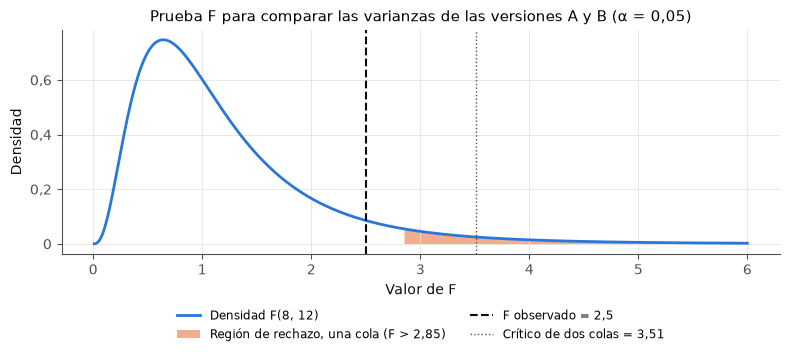

In [19]:
x = np.linspace(0.01, 6, 800)
y = stats.f.pdf(x, gl_num, gl_den)

fig, eje = plt.subplots(figsize=(8, 3.8))
eje.plot(x, y, color=AZUL, linewidth=2, label="Densidad F(8, 12)")
eje.fill_between(x, y, where=x >= F_critico_1, color=NARANJA, alpha=0.55, linewidth=0,
                 label=f"Región de rechazo, una cola (F > {coma(F_critico_1, 2)})")
eje.axvline(F, color=TEXTO, linewidth=1.5, linestyle="--", label=f"F observado = {coma(F, 1)}")
eje.axvline(F_critico_2, color=TEXTO_SECUNDARIO, linewidth=1, linestyle=":",
            label=f"Crítico de dos colas = {coma(F_critico_2, 2)}")
eje.set_xlabel("Valor de F")
eje.set_ylabel("Densidad")
eje.set_title("Prueba F para comparar las varianzas de las versiones A y B (α = 0,05)")
ejes_con_coma(eje)
eje.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=8.5)
fig.tight_layout()
guardar_figura(fig, "ej06_prueba_f_varianzas.png")
plt.show()

F = 2,5 queda por debajo del valor crítico de una cola, 2,85, y el valor p, 0,074, es mayor que 0,05, así que no rechazo H₀. Con dos colas la conclusión es la misma. La varianza de la versión nueva es menor en la muestra, pero con 9 y 13 mediciones esa diferencia todavía no alcanza para afirmar que la versión B estabilizó los tiempos de respuesta.

# Subtema 3. Muestreo y estimación

## Ejercicio 7. Tipos de muestreo

Este ejercicio es conceptual y lo desarrollo en el informe con un ejemplo de desarrollo de software para cada tipo de muestreo. No necesita cálculos.

## Ejercicio 8. Intervalo de confianza para la media con σ conocida

La desviación poblacional es conocida, σ = 36 ms, y la muestra es grande, n = 81 peticiones con x̄ = 205 ms. Por eso uso la normal: x̄ ± z·σ/√n. Construyo el intervalo al 90 %, 95 % y 99 % para ver cómo cambia su amplitud.

In [20]:
sigma_8, n_8, media_8 = 36, 81, 205
error_estandar_8 = sigma_8 / np.sqrt(n_8)
print(f"Error estándar = {sigma_8}/√{n_8} = {error_estandar_8}")

filas_8 = []
for confianza in (0.90, 0.95, 0.99):
    z = stats.norm.ppf(1 - (1 - confianza) / 2)
    margen = z * error_estandar_8
    inferior, superior = stats.norm.interval(confianza, loc=media_8, scale=error_estandar_8)
    filas_8.append({"confianza": f"{confianza:.0%}", "z": round(z, 4), "margen (ms)": round(margen, 2),
                    "límite inferior": round(inferior, 2), "límite superior": round(superior, 2),
                    "amplitud (ms)": round(superior - inferior, 2)})
ejercicio_8 = pd.DataFrame(filas_8)
ejercicio_8

Error estándar = 36/√81 = 4.0


,confianza,z,margen (ms),límite inferior,límite superior,amplitud (ms)
0,90%,1.6449,6.58,198.42,211.58,13.16
1,95%,1.9600,7.84,197.16,212.84,15.68
2,99%,2.5758,10.30,194.70,215.30,20.61


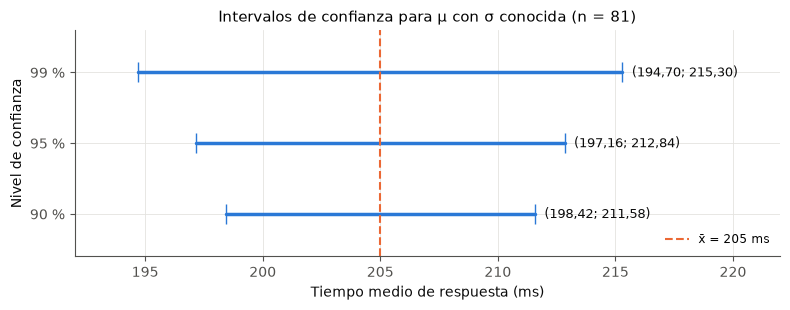

In [21]:
fig, eje = plt.subplots(figsize=(8, 3.2))
for i, fila in enumerate(filas_8):
    eje.plot([fila["límite inferior"], fila["límite superior"]], [i, i], color=AZUL, linewidth=2.5,
             solid_capstyle="round")
    eje.plot([fila["límite inferior"], fila["límite superior"]], [i, i], "|", color=AZUL, markersize=14)
    eje.text(fila["límite superior"] + 0.4, i,
             f"({coma(fila['límite inferior'], 2)}; {coma(fila['límite superior'], 2)})",
             va="center", color=TEXTO, fontsize=9)
eje.axvline(media_8, color=NARANJA, linewidth=1.5, linestyle="--", label="x̄ = 205 ms")
eje.set_yticks(range(3))
eje.set_yticklabels([f["confianza"].replace("%", " %") for f in filas_8])
eje.set_ylim(-0.6, 2.6)
eje.set_xlim(192, 222)
eje.set_xlabel("Tiempo medio de respuesta (ms)")
eje.set_ylabel("Nivel de confianza")
eje.set_title("Intervalos de confianza para μ con σ conocida (n = 81)")
ejes_con_coma(eje)
eje.yaxis.set_major_formatter(plt.FixedFormatter([f["confianza"].replace("%", " %") for f in filas_8]))
eje.legend(loc="lower right", fontsize=8.5)
fig.tight_layout()
guardar_figura(fig, "ej08_intervalos_sigma_conocida.png")
plt.show()

El error estándar es 4 ms en los tres casos; lo único que cambia es el valor z. Al pedir más confianza, z crece y el margen también: el intervalo pasa de 13,16 ms de ancho al 90 % a 20,61 ms al 99 %. Gano seguridad de capturar la media real a cambio de una estimación menos precisa.

## Ejercicio 9. Intervalo de confianza para la media con t de Student

La desviación poblacional se desconoce y la muestra es pequeña, n = 18 ejecuciones con x̄ = 12,4 min y s = 2,1 min. Por eso uso la t de Student con df = n − 1: x̄ ± t·s/√n.

In [22]:
n_9, media_9, s_9 = 18, 12.4, 2.1
gl_9 = n_9 - 1
t_9 = stats.t.ppf(0.975, gl_9)
error_estandar_9 = s_9 / np.sqrt(n_9)
margen_9 = t_9 * error_estandar_9
intervalo_9 = stats.t.interval(0.95, gl_9, loc=media_9, scale=error_estandar_9)

print(f"c) Grados de libertad: df = {n_9} − 1 = {gl_9}")
print(f"   t crítico (0,025 en cada cola) = {t_9:.4f}")
print(f"   Error estándar = {s_9}/√{n_9} = {error_estandar_9:.4f}")
print(f"   Margen de error = {margen_9:.4f} min")
print(f"a) IC del 95 %: ({intervalo_9[0]:.2f}; {intervalo_9[1]:.2f}) min")
print(f"   Para comparar, z = 1,96 daría un margen de {1.96 * error_estandar_9:.4f} min")

c) Grados de libertad: df = 18 − 1 = 17
   t crítico (0,025 en cada cola) = 2.1098
   Error estándar = 2.1/√18 = 0.4950
   Margen de error = 1.0443 min
a) IC del 95 %: (11.36; 13.44) min
   Para comparar, z = 1,96 daría un margen de 0.9702 min


Con un 95 % de confianza, la duración media del proceso por lotes está entre 11,36 y 13,44 minutos. El margen con t (1,044 min) es más amplio que el que daría z (0,970 min), porque la t compensa la incertidumbre extra de estimar σ con una muestra pequeña.

## Ejercicio 10. Intervalo de confianza para una proporción y tamaño de muestra

De 400 usuarios encuestados, 150 activaron la función. La proporción muestral es p′ = x/n y el intervalo es p′ ± z·√(p′q′/n). Para el tamaño de muestra uso n = z²pq/E² con p = 0,5 y redondeo hacia arriba.

In [23]:
x_10, n_10 = 150, 400
p_10 = x_10 / n_10
q_10 = 1 - p_10
z_95 = stats.norm.ppf(0.975)

print(f"Condiciones: n·p′ = {n_10 * p_10:.0f} y n·q′ = {n_10 * q_10:.0f} (las dos mayores que 5)")
error_estandar_10 = np.sqrt(p_10 * q_10 / n_10)
margen_10 = z_95 * error_estandar_10
intervalo_10 = (p_10 - margen_10, p_10 + margen_10)
print(f"a) p′ = {p_10}, error estándar = {error_estandar_10:.4f}, margen = {margen_10:.4f}")
print(f"   IC del 95 %: ({intervalo_10[0]:.4f}; {intervalo_10[1]:.4f})")

E_10, p_conservador = 0.03, 0.5
n_tabla = 1.96 ** 2 * p_conservador * (1 - p_conservador) / E_10 ** 2
n_exacto = z_95 ** 2 * p_conservador * (1 - p_conservador) / E_10 ** 2
print(f"b) n = 1,96²·0,5·0,5/0,03² = {n_tabla:.2f} → {int(np.ceil(n_tabla))} usuarios")
print(f"   Con z exacto ({z_95:.4f}): n = {n_exacto:.2f} → {int(np.ceil(n_exacto))} usuarios")

Condiciones: n·p′ = 150 y n·q′ = 250 (las dos mayores que 5)
a) p′ = 0.375, error estándar = 0.0242, margen = 0.0474
   IC del 95 %: (0.3276; 0.4224)
b) n = 1,96²·0,5·0,5/0,03² = 1067.11 → 1068 usuarios
   Con z exacto (1.9600): n = 1067.07 → 1068 usuarios


Entre el 32,8 % y el 42,2 % de los usuarios estaría adoptando la función, con un 95 % de confianza. Para estimar esa proporción con un margen del 3 % se necesitan 1.068 usuarios, casi el triple de los 400 encuestados.

# Subtema 4. Prueba de hipótesis

## Ejercicio 11. Prueba para la media (dos colas)

Se afirma que el tiempo medio de respuesta del endpoint es 150 ms. La muestra es de 40 mediciones con x̄ = 158 ms y s = 24 ms, y α = 0,05.

H₀: μ = 150  frente a  Hₐ: μ ≠ 150

Como σ es desconocida, uso la t de Student con df = 39. Como n > 30, también muestro el resultado con z para comparar.

In [24]:
mu_0, n_11, media_11, s_11, alfa = 150, 40, 158, 24, 0.05
gl_11 = n_11 - 1
error_estandar_11 = s_11 / np.sqrt(n_11)
t_11 = (media_11 - mu_0) / error_estandar_11
t_critico_11 = stats.t.ppf(1 - alfa / 2, gl_11)
p_11 = 2 * stats.t.sf(abs(t_11), gl_11)

z_critico_11 = stats.norm.ppf(1 - alfa / 2)
p_11_z = 2 * stats.norm.sf(abs(t_11))

print(f"Error estándar = {s_11}/√{n_11} = {error_estandar_11:.4f}")
print(f"b) t = ({media_11} − {mu_0})/{error_estandar_11:.4f} = {t_11:.4f}, df = {gl_11}")
print(f"c) Con t: crítico = ±{t_critico_11:.4f} | valor p = {p_11:.4f} | rechazo H0: {abs(t_11) > t_critico_11}")
print(f"   Con z: crítico = ±{z_critico_11:.4f} | valor p = {p_11_z:.4f} | rechazo H0: {abs(t_11) > z_critico_11}")

Error estándar = 24/√40 = 3.7947
b) t = (158 − 150)/3.7947 = 2.1082, df = 39
c) Con t: crítico = ±2.0227 | valor p = 0.0415 | rechazo H0: True
   Con z: crítico = ±1.9600 | valor p = 0.0350 | rechazo H0: True


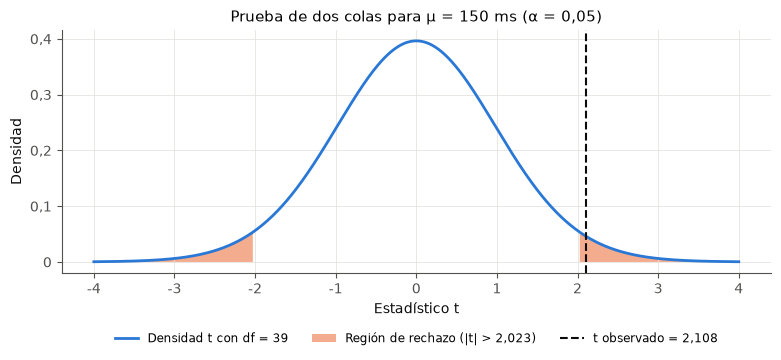

In [25]:
x = np.linspace(-4, 4, 800)
y = stats.t.pdf(x, gl_11)

fig, eje = plt.subplots(figsize=(8, 3.8))
eje.plot(x, y, color=AZUL, linewidth=2, label="Densidad t con df = 39")
eje.fill_between(x, y, where=np.abs(x) >= t_critico_11, color=NARANJA, alpha=0.55, linewidth=0,
                 label=f"Región de rechazo (|t| > {coma(t_critico_11, 3)})")
eje.axvline(t_11, color=TEXTO, linewidth=1.5, linestyle="--", label=f"t observado = {coma(t_11, 3)}")
eje.set_xlabel("Estadístico t")
eje.set_ylabel("Densidad")
eje.set_title("Prueba de dos colas para μ = 150 ms (α = 0,05)")
ejes_con_coma(eje)
eje.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=8.5)
fig.tight_layout()
guardar_figura(fig, "ej11_prueba_t_dos_colas.png")
plt.show()

El estadístico t = 2,108 cae en la región de rechazo y el valor p, 0,041, es menor que 0,05, así que rechazo H₀. Con z la decisión es la misma. La evidencia contradice la afirmación: el tiempo medio real del endpoint es distinto de 150 ms, y como la media muestral es mayor, el servicio está respondiendo más lento de lo prometido.

## Ejercicio 12. Prueba para la proporción (una cola)

El equipo afirma que al menos el 85 % de los despliegues se completa sin intervención manual. En la muestra, 160 de 200 lo hicieron. Con α = 0,05:

H₀: p ≥ 0,85  frente a  Hₐ: p < 0,85

Es una prueba de cola izquierda. El estadístico es z = (p′ − p₀)/√(p₀q₀/n), con el error estándar calculado con p₀.

In [26]:
p_0, x_12, n_12, alfa = 0.85, 160, 200, 0.05
q_0 = 1 - p_0
p_12 = x_12 / n_12

print(f"Condiciones: n·p0 = {n_12 * p_0:.0f} y n·q0 = {n_12 * q_0:.0f} (las dos mayores que 5)")
error_estandar_12 = np.sqrt(p_0 * q_0 / n_12)
z_12 = (p_12 - p_0) / error_estandar_12
z_critico_12 = stats.norm.ppf(alfa)
p_valor_12 = stats.norm.cdf(z_12)

print(f"p′ = {x_12}/{n_12} = {p_12}")
print(f"Error estándar = √(0,85·0,15/200) = {error_estandar_12:.4f}")
print(f"b) z = ({p_12} − {p_0})/{error_estandar_12:.4f} = {z_12:.4f}")
print(f"c) z crítico = {z_critico_12:.4f} | valor p = {p_valor_12:.4f} | rechazo H0: {z_12 < z_critico_12}")

Condiciones: n·p0 = 170 y n·q0 = 30 (las dos mayores que 5)
p′ = 160/200 = 0.8
Error estándar = √(0,85·0,15/200) = 0.0252
b) z = (0.8 − 0.85)/0.0252 = -1.9803
c) z crítico = -1.6449 | valor p = 0.0238 | rechazo H0: True


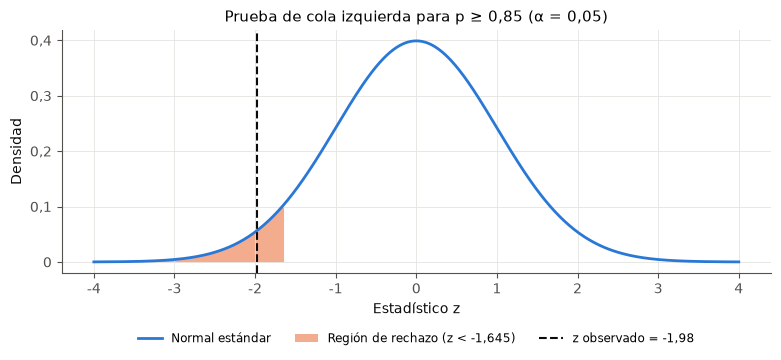

In [27]:
x = np.linspace(-4, 4, 800)
y = stats.norm.pdf(x)

fig, eje = plt.subplots(figsize=(8, 3.8))
eje.plot(x, y, color=AZUL, linewidth=2, label="Normal estándar")
eje.fill_between(x, y, where=x <= z_critico_12, color=NARANJA, alpha=0.55, linewidth=0,
                 label=f"Región de rechazo (z < {coma(z_critico_12, 3)})")
eje.axvline(z_12, color=TEXTO, linewidth=1.5, linestyle="--", label=f"z observado = {coma(z_12, 2)}")
eje.set_xlabel("Estadístico z")
eje.set_ylabel("Densidad")
eje.set_title("Prueba de cola izquierda para p ≥ 0,85 (α = 0,05)")
ejes_con_coma(eje)
eje.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=8.5)
fig.tight_layout()
guardar_figura(fig, "ej12_prueba_z_proporcion.png")
plt.show()

El estadístico z = −1,98 queda a la izquierda del valor crítico −1,645 y el valor p, 0,024, es menor que 0,05, así que rechazo H₀. Con esta muestra no se sostiene que al menos el 85 % de los despliegues sea automático; el dato observado, 80 %, está por debajo de forma significativa.

## Ejercicio 13. Errores tipo I y II

Este ejercicio es conceptual y lo desarrollo en el informe con el caso de una alarma de integración continua que bloquea despliegues. No necesita cálculos.

# Subtema 5. Aplicación con la base de datos del curso

## Ejercicio 14. Normal, estimación y prueba de hipótesis con `Duracion_Despliegue_min`

Trabajo con la columna `Duracion_Despliegue_min` de la hoja `Datos`, que ya validé en la sección 1: 1.000 registros, en minutos y sin valores faltantes.

### a) Media y desviación estándar con numpy

`np.std` calcula por defecto la desviación poblacional, que divide entre n (`ddof=0`). Como estos 1.000 registros son datos observados y la desviación se usa como estimador, reporto la desviación muestral, que divide entre n − 1 (`ddof=1`), y muestro también la poblacional para comparar. Con n = 1.000 la diferencia es muy pequeña.

In [28]:
duraciones = datos[COLUMNA].to_numpy()

n_14 = duraciones.size
media_14 = np.mean(duraciones)
desviacion_muestral = np.std(duraciones, ddof=1)
desviacion_poblacional = np.std(duraciones, ddof=0)

print(f"n = {n_14}")
print(f"Media = {media_14:.4f} min")
print(f"Desviación estándar muestral (ddof=1) = {desviacion_muestral:.4f} min  <- la que reporto")
print(f"Desviación estándar poblacional (ddof=0) = {desviacion_poblacional:.4f} min")
print(f"Mínimo = {duraciones.min()} min | Mediana = {np.median(duraciones)} min | Máximo = {duraciones.max()} min")

n = 1000
Media = 14.0208 min
Desviación estándar muestral (ddof=1) = 3.9608 min  <- la que reporto
Desviación estándar poblacional (ddof=0) = 3.9588 min
Mínimo = 2.0 min | Mediana = 14.1 min | Máximo = 27.4 min


### b) Histograma frente a la densidad normal

Dibujo el histograma en escala de densidad, para que su área total sea 1 y se pueda comparar con la curva, y encima la densidad de una normal con la media y la desviación muestral que acabo de calcular, usando `scipy.stats.norm`.

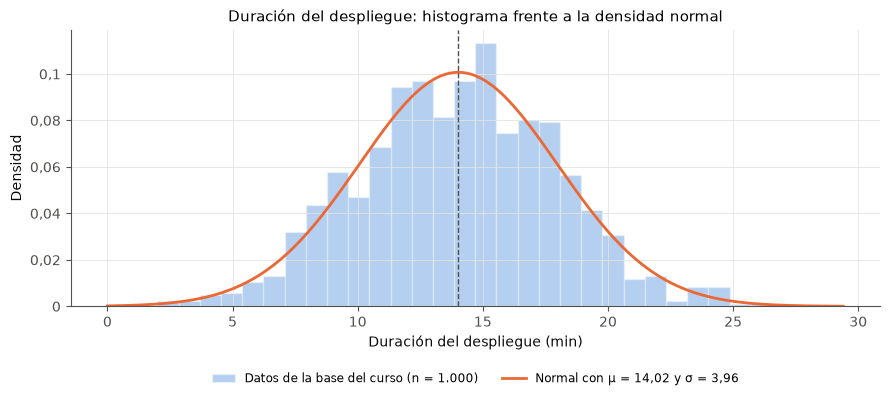

In [29]:
normal_14 = stats.norm(loc=media_14, scale=desviacion_muestral)
x = np.linspace(duraciones.min() - 2, duraciones.max() + 2, 600)

fig, eje = plt.subplots(figsize=(9, 4.2))
eje.hist(duraciones, bins=30, density=True, color=AZUL, alpha=0.35, edgecolor="white", linewidth=1,
         label="Datos de la base del curso (n = 1.000)")
eje.plot(x, normal_14.pdf(x), color=NARANJA, linewidth=2,
         label=f"Normal con μ = {coma(media_14, 2)} y σ = {coma(desviacion_muestral, 2)}")
eje.axvline(media_14, color=TEXTO_SECUNDARIO, linewidth=1, linestyle="--")
eje.set_xlabel("Duración del despliegue (min)")
eje.set_ylabel("Densidad")
eje.set_title("Duración del despliegue: histograma frente a la densidad normal")
ejes_con_coma(eje)
eje.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=8.5)
fig.tight_layout()
guardar_figura(fig, "ej14_histograma_normal.png")
plt.show()

Para no quedarme solo con la impresión visual, calculo la asimetría, la curtosis en exceso, que vale 0 en una normal, y el porcentaje de datos a una, dos y tres desviaciones de la media, para compararlo con la regla empírica del ejercicio 2.

In [30]:
print(f"Asimetría = {stats.skew(duraciones):.4f}")
print(f"Curtosis en exceso = {stats.kurtosis(duraciones):.4f}")
for k, esperado in zip((1, 2, 3), (68, 95, 99.7)):
    dentro = np.mean(np.abs(duraciones - media_14) <= k * desviacion_muestral)
    print(f"Dentro de μ ± {k}σ: {dentro:.1%} de los datos (regla empírica: {esperado} %)")

Asimetría = 0.0517
Curtosis en exceso = 0.0068
Dentro de μ ± 1σ: 68.6% de los datos (regla empírica: 68 %)
Dentro de μ ± 2σ: 95.8% de los datos (regla empírica: 95 %)
Dentro de μ ± 3σ: 99.7% de los datos (regla empírica: 99.7 %)


El histograma sigue de cerca la curva normal: tiene un solo pico alrededor de 14 minutos, es casi simétrico y sus colas bajan de forma parecida a las de la curva. La asimetría (0,05) y la curtosis en exceso (0,01) están muy cerca de 0, y los porcentajes dentro de una, dos y tres desviaciones (68,6 %, 95,8 % y 99,7 %) casi coinciden con la regla empírica. Por eso es razonable modelar la duración de los despliegues con una normal de media 14,02 min y desviación 3,96 min, y usar la t de Student en los literales c y d.

### c) Muestra aleatoria de 50 registros e intervalo de confianza del 95 %

Tomo una muestra aleatoria simple de 50 duraciones, sin reemplazo, con la **semilla 2026** para que el resultado sea reproducible: cualquiera que ejecute este notebook obtiene los mismos 50 registros. Como no conozco σ y la estimo con s, el intervalo usa la t de Student con df = 50 − 1 = 49.

In [31]:
SEMILLA = 2026
generador = np.random.default_rng(SEMILLA)
muestra = generador.choice(duraciones, size=50, replace=False)

n_m = muestra.size
media_m = muestra.mean()
s_m = muestra.std(ddof=1)
error_estandar_m = s_m / np.sqrt(n_m)

print(f"Semilla = {SEMILLA}, n = {n_m}")
print(f"Media muestral = {media_m:.4f} min | Desviación muestral = {s_m:.4f} min")
print(f"Error estándar = {s_m:.4f}/√{n_m} = {error_estandar_m:.4f} min")
print("Primeros 10 valores de la muestra:", muestra[:10])

Semilla = 2026, n = 50
Media muestral = 14.3900 min | Desviación muestral = 4.2477 min
Error estándar = 4.2477/√50 = 0.6007 min
Primeros 10 valores de la muestra: [21.2 12.   9.1 17.4 16.2  7.3 19.3 18.3 14.1 17.8]


In [32]:
gl_m = n_m - 1
intervalo_m = stats.t.interval(0.95, gl_m, loc=media_m, scale=error_estandar_m)

# Comprobación a mano con el t de tabla
t_tabla = stats.t.ppf(0.975, gl_m)
margen_m = t_tabla * error_estandar_m
print(f"IC del 95 % con scipy.stats.t.interval: ({intervalo_m[0]:.4f}; {intervalo_m[1]:.4f}) min")
print(f"A mano: t(0,025; {gl_m}) = {t_tabla:.4f}, margen = {margen_m:.4f}, "
      f"IC = ({media_m - margen_m:.4f}; {media_m + margen_m:.4f}) min")
print(f"¿Contiene la media de las 1.000 filas ({media_14:.4f} min)? {intervalo_m[0] <= media_14 <= intervalo_m[1]}")

IC del 95 % con scipy.stats.t.interval: (13.1828; 15.5972) min
A mano: t(0,025; 49) = 2.0096, margen = 1.2072, IC = (13.1828; 15.5972) min
¿Contiene la media de las 1.000 filas (14.0208 min)? True


Con un 95 % de confianza, la duración media de los despliegues está entre 13,18 y 15,60 minutos. En este caso el intervalo sí contiene la media de las 1.000 filas, 14,02 min, aunque eso no está garantizado para cualquier muestra: el 95 % se refiere a que el método acierta en el 95 % de las muestras posibles.

### d) Prueba t de una muestra contra 15 minutos

El enunciado propone como ejemplo un valor de referencia de 30 minutos. Elegí **15 minutos**, presentado como la meta del equipo para la duración media de un despliegue, porque está cerca de la media observada y por eso la prueba es informativa. Con 30 minutos el rechazo sería obvio, como muestro abajo.

H₀: μ = 15 min  frente a  Hₐ: μ ≠ 15 min, con α = 0,05.

In [33]:
VALOR_REFERENCIA = 15
alfa = 0.05
prueba = stats.ttest_1samp(muestra, popmean=VALOR_REFERENCIA)

t_a_mano = (media_m - VALOR_REFERENCIA) / error_estandar_m
print(f"t = ({media_m:.4f} − {VALOR_REFERENCIA})/{error_estandar_m:.4f} = {t_a_mano:.4f}  (a mano)")
print(f"scipy.stats.ttest_1samp: t = {prueba.statistic:.4f}, df = {prueba.df}, valor p = {prueba.pvalue:.4f}")
print(f"t crítico = ±{t_tabla:.4f}")
print("Decisión:", "rechazo H0" if prueba.pvalue < alfa else "no rechazo H0", f"(valor p {'<' if prueba.pvalue < alfa else '≥'} {alfa})")

t = (14.3900 − 15)/0.6007 = -1.0155  (a mano)
scipy.stats.ttest_1samp: t = -1.0155, df = 49, valor p = 0.3149
t crítico = ±2.0096
Decisión: no rechazo H0 (valor p ≥ 0.05)


In [34]:
# Comparación con el valor de 30 minutos que proponía el enunciado
prueba_30 = stats.ttest_1samp(muestra, popmean=30)
print(f"Contra 30 min: t = {prueba_30.statistic:.2f}, valor p = {prueba_30.pvalue:.2e}")

Contra 30 min: t = -25.99, valor p = 2.58e-30


El valor p, 0,315, es mucho mayor que 0,05, así que no rechazo H₀: con esta muestra no hay evidencia de que la duración media de los despliegues sea distinta de la meta de 15 minutos. El intervalo del literal c lleva a la misma conclusión, porque contiene el 15. Contra 30 minutos el estadístico es cercano a −26 y el valor p es prácticamente cero, un resultado que no aporta información porque ningún despliegue de la base llega a 30 minutos: el máximo es 27,4.